In [1]:
import pandas as pd

datos = pd.read_csv("5k.csv")

In [2]:
datos.head()

,km_semanales,tiempo_5k_min
0,6,42.7
1,28,26.4
2,24,27.9
3,18,29.9
4,17,33.9


In [4]:
datos.head(7)

,km_semanales,tiempo_5k_min
0,6,42.7
1,28,26.4
2,24,27.9
3,18,29.9
4,17,33.9
5,31,28.9
6,6,37.0


In [5]:
datos.shape

(60, 2)

In [6]:
datos.describe()

,km_semanales,tiempo_5k_min
count,60.000000,60.000000
mean,20.300000,30.883333
std,8.836174,4.365705
min,5.000000,24.400000
25%,14.250000,27.575000
50%,20.500000,30.050000
75%,28.000000,33.825000
max,35.000000,42.700000


In [7]:
datos.isnull().sum()

km_semanales     0
tiempo_5k_min    0
dtype: int64

In [8]:
import matplotlib.pyplot as plt

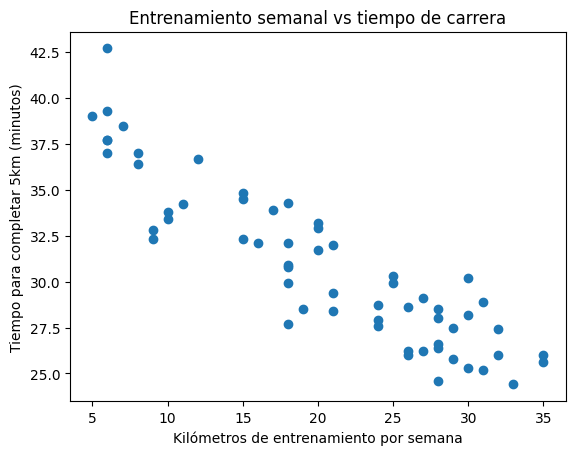

In [9]:
plt.scatter(datos["km_semanales"],datos["tiempo_5k_min"])

plt.xlabel("Kilómetros de entrenamiento por semana")
plt.ylabel("Tiempo para completar 5km (minutos)")
plt.title("Entrenamiento semanal vs tiempo de carrera")

plt.show()

In [10]:
X = datos[["km_semanales"]]
y = datos["tiempo_5k_min"]

In [11]:
# Estoy importando todo lo necesario para hacer una regresión lineal de la librería sklearn
from sklearn.linear_model import LinearRegression

In [13]:
# Aquí ya tengo todo listo para entrenar mi modelo
modelo = LinearRegression()

In [14]:
# Aquí ya le doy los datos, primero tiene que ir X y después y
modelo.fit(X,y)

LinearRegression()

In [15]:
print("Pendiente:",modelo.coef_[0])
print("Intercepto:",modelo.intercept_)

Pendiente: -0.4461424912082665
Intercepto: 39.940025904861145


In [16]:
# Generando predicciones de todos los renglones (no es el valor real es la predicción)
predicciones = modelo.predict(X)

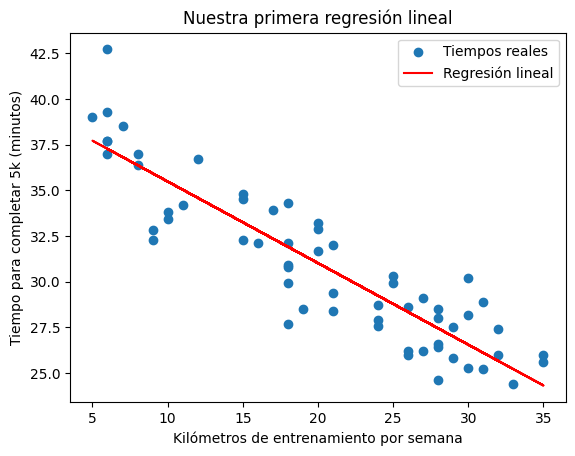

In [17]:
plt.scatter(X["km_semanales"],y, label="Tiempos reales")

plt.plot(
    X["km_semanales"],
    predicciones,
    color = "red",
    label = "Regresión lineal"
)

plt.xlabel("Kilómetros de entrenamiento por semana")
plt.ylabel("Tiempo para completar 5k (minutos)")
plt.title("Nuestra primera regresión lineal")

plt.legend()
plt.show()

In [25]:
nuevo_corredor = pd.DataFrame({
    "km_semanales":[18]
})

tiempo_estimado = modelo.predict(nuevo_corredor)

print("Tiempo estimado:", round(tiempo_estimado[0],1),"minutos")

Tiempo estimado: 31.9 minutos


In [27]:
pendiente = modelo.coef_[0]
intercepto = modelo.intercept_

In [28]:
resultado_manual = intercepto + (pendiente * 18)

In [29]:
print("Predicción con la fórmula:",round(resultado_manual,1))
print("Predicción de modelo:", round(tiempo_estimado[0],1))

Predicción con la fórmula: 31.9
Predicción de modelo: 31.9


In [33]:
nuevos_corredores = pd.DataFrame({
    "km_semanales" : [8,18,30]
})

nuevos_corredores["tiempo_estimado"] = modelo.predict(
    nuevos_corredores[["km_semanales"]]
)

nuevos_corredores

,km_semanales,tiempo_estimado
0,8,36.370886
1,18,31.909461
2,30,26.555751


In [34]:
from sklearn.metrics import mean_absolute_error

In [37]:
error_promedio = mean_absolute_error(y, predicciones)
round(error_promedio,2)

1.55